# Chapter 10: Stage 6B — Building a Complete Document Q&A System with RAG (Retrieval-Augmented Generation)

**Assalam-o-Alaikum!** Is chapter mein hum **Advanced Project 13: Document-Based Question-Answering Assistant (RAG)** banayenge jo company ke official documents (`datasets/company_knowledge_base.json`) mein se **Vector Search** ke zariye exact policy dhoond kar **Grounded Answer with Citations** deta hai!

### RAG Pipeline Ke 4 Steps
```text
[User Question] ---> (1. Embed Query) ---> (2. Vector Search over Knowledge Base)
                                                      |
[Grounded Answer + Citation] <--- (4. Generator) <--- (3. Top-K Relevant Docs)
```

In [1]:
import json
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

### Step 1 — Load Company Knowledge Base (`datasets/company_knowledge_base.json`)

In [2]:
with open("datasets/company_knowledge_base.json", "r", encoding="utf-8") as f:
    kb_docs = json.load(f)

kb_df = pd.DataFrame(kb_docs)
kb_df

,doc_id,title,content
0,POL-01,Return and Refund Policy,Customers can return any unopened product within 14 days of delivery for a 100% full refund. Defective electronics are eligible for free replacement within 30 days.
1,POL-02,Shipping and Delivery Charges,"Standard delivery across Pakistan takes 2 to 4 business days. Shipping is free on orders above 3000 PKR, otherwise a flat fee of 250 PKR applies."
2,POL-03,AI Scholarship and Course Policy,Students who score above 85% in the final capstone project receive an AI Engineering Certificate and a 50% scholarship for advanced cloud deployment labs.
3,POL-04,Customer Support Escalation Rules,"Billing disputes above 10,000 PKR require human manager approval before issuing an automated refund."


### Step 2 — Build Vector Search Index & Retrieve Top-Matching Document with Citations

In [3]:
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
doc_texts = [f"{d['title']} {d['content']}" for d in kb_docs]
doc_vectors = vectorizer.fit_transform(doc_texts).toarray()

def answer_question_with_rag(user_query, threshold=0.10):
    q_vec = vectorizer.transform([user_query]).toarray()[0]
    scores = doc_vectors @ q_vec
    best_idx = int(np.argmax(scores))
    best_score = float(scores[best_idx])
    if best_score < threshold:
        return {
            "query": user_query,
            "answer": "Maazrat! Is sawal ka jawab company knowledge base mein maujood nahi hai.",
            "source_doc_id": None,
            "similarity_score": round(best_score, 3),
        }
    matched_doc = kb_docs[best_idx]
    return {
        "query": user_query,
        "answer": f"{matched_doc['content']} (Source: [{matched_doc['doc_id']}] {matched_doc['title']})",
        "source_doc_id": matched_doc["doc_id"],
        "similarity_score": round(best_score, 3),
    }

for q in [
    "How many days do I have to return a product for a full refund?",
    "When is shipping free across Pakistan?",
    "Can I get a scholarship for the cloud deployment labs?",
    "What is the weather in Tokyo tomorrow?",
]:
    res = answer_question_with_rag(q)
    print(f"Q: {res['query']} -> A: {res['answer']} (Score: {res['similarity_score']})")

Q: How many days do I have to return a product for a full refund? -> A: Customers can return any unopened product within 14 days of delivery for a 100% full refund. Defective electronics are eligible for free replacement within 30 days. (Source: [POL-01] Return and Refund Policy) (Score: 0.468)
Q: When is shipping free across Pakistan? -> A: Standard delivery across Pakistan takes 2 to 4 business days. Shipping is free on orders above 3000 PKR, otherwise a flat fee of 250 PKR applies. (Source: [POL-02] Shipping and Delivery Charges) (Score: 0.44)
Q: Can I get a scholarship for the cloud deployment labs? -> A: Students who score above 85% in the final capstone project receive an AI Engineering Certificate and a 50% scholarship for advanced cloud deployment labs. (Source: [POL-03] AI Scholarship and Course Policy) (Score: 0.408)
Q: What is the weather in Tokyo tomorrow? -> A: Maazrat! Is sawal ka jawab company knowledge base mein maujood nahi hai. (Score: 0.0)


### Step 3 — Visualize Query-to-Document Cosine Similarity Scores
Chalein dekhte hain ke jab user `"refund policy"` ke bare mein sawal poochta hai toh Vector Search har document ko kitna similarity score deta hai:

,Doc_ID,Title,Similarity_Score
0,POL-01,Return and Refund Policy,0.468
1,POL-02,Shipping and Delivery Charges,0.043
2,POL-03,AI Scholarship and Course Policy,0.000
3,POL-04,Customer Support Escalation Rules,0.050


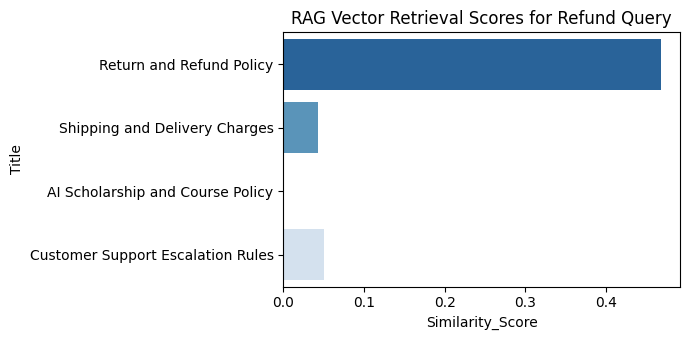

In [4]:
sample_q = "How many days do I have to return a product for a full refund?"
q_vec = vectorizer.transform([sample_q]).toarray()[0]
doc_scores = np.round(doc_vectors @ q_vec, 3)

score_df = pd.DataFrame({
    "Doc_ID": [d["doc_id"] for d in kb_docs],
    "Title": [d["title"] for d in kb_docs],
    "Similarity_Score": doc_scores,
})

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(7, 3.5))
sns.barplot(x="Similarity_Score", y="Title", hue="Title", data=score_df, palette="Blues_r", legend=False)
plt.title("RAG Vector Retrieval Scores for Refund Query")
plt.tight_layout()
plt.show()
score_df

### Step 4 — Preventing Hallucinations with Similarity Thresholds
Dekhein ke jab user ne `"What is the weather in Tokyo tomorrow?"` poocha, toh `Similarity_Score = 0.0` aaya jo hamare `threshold = 0.10` se kam tha — is liye RAG system ne jhooti kahani (**Hallucination**) gharne ke bajaye saaf bata diya ke yeh maloomat company documents mein nahi hai!

### Step 5 — Practical Student Exercise: Add a New Policy Document & Query It Live

In [5]:
# Practical Exercise — Working Solution: Add a Warranty Policy document and query it
kb_extended = kb_docs + [{
    "doc_id": "POL-05",
    "title": "Laptop Battery Warranty Policy",
    "content": "All laptop batteries include a 12-month official replacement warranty if capacity drops below 80 percent.",
}]
vec_ext = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
mat_ext = vec_ext.fit_transform([f"{d['title']} {d['content']}" for d in kb_extended]).toarray()

q_bat = "What is the warranty period for laptop batteries?"
scores_bat = mat_ext @ vec_ext.transform([q_bat]).toarray()[0]
best_doc = kb_extended[int(np.argmax(scores_bat))]
print("Matched Doc ID:", best_doc["doc_id"], "| Answer:", best_doc["content"])

Matched Doc ID: POL-05 | Answer: All laptop batteries include a 12-month official replacement warranty if capacity drops below 80 percent.


### Chapter 10 Revision Quiz
1. **RAG ka sab se bada faida kya hai?** Bina model ko re-train kiye taaza company documents par 100% grounded aur cited jawabat dena.
2. **Document Chunking kyun zaroori hoti hai?** Kyunke ek 200-page PDF ko ek saath vector mein badalne se barik details kho jati hain; 300–500 words ke chunks banane se exact paragraph milta hai.